In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

batches_df = pd.read_csv(DATA_DIR / "inventory_batches.csv")
products_df = pd.read_csv(DATA_DIR / "products.csv")

print("Inventory batches:", batches_df.shape)
print("Products:", products_df.shape)

Inventory batches: (2000, 16)
Products: (10, 6)


In [2]:
feature_df = batches_df.copy()

print("Original dataset:", batches_df.shape)
print("Feature dataset:", feature_df.shape)

Original dataset: (2000, 16)
Feature dataset: (2000, 16)


In [10]:
feature_df["inventory_surplus"] = (
    feature_df["quantity_remaining"]
    - feature_df["expected_demand_before_expiry"]
)

display(
    feature_df[
        [
            "batch_id",
            "quantity_remaining",
            "expected_demand_before_expiry",
            "inventory_surplus"
        ]
    ].head(10)
)

,batch_id,quantity_remaining,expected_demand_before_expiry,inventory_surplus
0,5001,72,117,-45
1,5002,123,37,86
2,5003,3,38,-35
3,5004,141,0,141
4,5005,52,144,-92
5,5006,36,36,0
6,5007,73,9,64
7,5008,0,146,-146
8,5009,28,56,-28
9,5010,86,23,63


In [11]:
feature_df["stock_coverage_days"] = np.where(
    feature_df["avg_daily_sales_7d"] > 0,
    feature_df["quantity_remaining"] /
    feature_df["avg_daily_sales_7d"],
    np.nan
)

display(
    feature_df[
        [
            "batch_id",
            "quantity_remaining",
            "avg_daily_sales_7d",
            "stock_coverage_days"
        ]
    ].head(10)
)

,batch_id,quantity_remaining,avg_daily_sales_7d,stock_coverage_days
0,5001,72,23.38,3.079555
1,5002,123,36.86,3.336951
2,5003,3,12.67,0.236780
3,5004,141,14.52,9.710744
4,5005,52,13.09,3.972498
5,5006,36,36.04,0.998890
6,5007,73,9.34,7.815846
7,5008,0,36.56,0.000000
8,5009,28,11.11,2.520252
9,5010,86,11.34,7.583774


In [5]:
feature_df["remaining_stock_pct"] = (
    feature_df["quantity_remaining"] /
    feature_df["initial_quantity"]
) * 100

display(
    feature_df[
        [
            "batch_id",
            "initial_quantity",
            "quantity_remaining",
            "remaining_stock_pct"
        ]
    ].head(10)
)

,batch_id,initial_quantity,quantity_remaining,remaining_stock_pct
0,5001,140,72,51.428571
1,5002,140,123,87.857143
2,5003,22,3,13.636364
3,5004,141,141,100.000000
4,5005,139,52,37.410072
5,5006,59,36,61.016949
6,5007,80,73,91.250000
7,5008,46,0,0.000000
8,5009,57,28,49.122807
9,5010,99,86,86.868687


In [6]:
conditions = [
    feature_df["days_to_expiry"] < 0,
    feature_df["days_to_expiry"] == 0,
    feature_df["days_to_expiry"] <= 2,
    feature_df["days_to_expiry"] <= 5,
    feature_df["days_to_expiry"] > 5
]

choices = [
    "Expired",
    "Expires Today",
    "Critical",
    "Warning",
    "Safe Time Window"
]

feature_df["expiry_urgency"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

display(
    feature_df["expiry_urgency"].value_counts()
)

expiry_urgency
Warning             519
Safe Time Window    454
Critical            418
Expired             409
Expires Today       200
Name: count, dtype: int64

In [7]:
feature_df["profit_per_unit"] = (
    feature_df["unit_price"] - feature_df["unit_cost"]
)

feature_df["gross_margin_pct"] = np.where(
    feature_df["unit_price"] > 0,
    (
        feature_df["profit_per_unit"] /
        feature_df["unit_price"]
    ) * 100,
    np.nan
)

display(
    feature_df[
        [
            "batch_id",
            "unit_price",
            "unit_cost",
            "profit_per_unit",
            "gross_margin_pct"
        ]
    ].head(10)
)

,batch_id,unit_price,unit_cost,profit_per_unit,gross_margin_pct
0,5001,45.0,28.0,17.0,37.777778
1,5002,45.0,28.0,17.0,37.777778
2,5003,32.0,24.0,8.0,25.000000
3,5004,40.0,26.0,14.0,35.000000
4,5005,120.0,78.0,42.0,35.000000
5,5006,95.0,61.0,34.0,35.789474
6,5007,55.0,34.0,21.0,38.181818
7,5008,45.0,28.0,17.0,37.777778
8,5009,55.0,34.0,21.0,38.181818
9,5010,32.0,24.0,8.0,25.000000


In [8]:
feature_df = feature_df.merge(
    products_df[
        ["product_id", "product_name", "shelf_life_days"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("New feature dataset shape:", feature_df.shape)

display(
    feature_df[
        [
            "batch_id",
            "product_id",
            "product_name",
            "shelf_life_days",
            "days_to_expiry"
        ]
    ].head(10)
)

New feature dataset shape: (2000, 24)


,batch_id,product_id,product_name,shelf_life_days,days_to_expiry
0,5001,1006,Tomatoes 1kg,7,5
1,5002,1006,Tomatoes 1kg,7,1
2,5003,1001,Milk 500ml,5,3
3,5004,1003,Bread Loaf,4,-1
4,5005,1007,Apple 1kg,14,11
5,5006,1008,Orange Juice 1L,30,1
6,5007,1010,Muffin Pack,5,1
7,5008,1006,Tomatoes 1kg,7,4
8,5009,1010,Muffin Pack,5,5
9,5010,1001,Milk 500ml,5,2


In [9]:
print("Missing product names:",
      feature_df["product_name"].isna().sum())

print("Missing inventory surplus:",
      feature_df["inventory_surplus"].isna().sum())

print("Missing expiry urgency:",
      feature_df["expiry_urgency"].isna().sum())

print("Duplicate batch IDs:",
      feature_df["batch_id"].duplicated().sum())

display(
    feature_df[
        [
            "inventory_surplus",
            "stock_coverage_days",
            "remaining_stock_pct",
            "profit_per_unit",
            "gross_margin_pct"
        ]
    ].describe().round(2)
)

feature_df.to_csv(
    PROCESSED_DIR / "inventory_features.csv",
    index=False
)

print("Feature dataset saved successfully!")

Missing product names: 0
Missing inventory surplus: 0
Missing expiry urgency: 0
Duplicate batch IDs: 0


,inventory_surplus,stock_coverage_days,remaining_stock_pct,profit_per_unit,gross_margin_pct
count,2000.00,2000.00,2000.00,2000.00,2000.00
mean,-24.22,4.19,58.77,19.68,33.78
std,159.10,4.71,39.69,10.48,4.64
min,-949.00,0.00,0.00,8.00,25.00
25%,-62.00,0.40,13.64,12.00,31.67
50%,17.00,2.88,72.41,17.00,35.00
75%,71.00,6.26,98.34,23.00,37.78
max,150.00,28.05,100.00,42.00,40.00


Feature dataset saved successfully!


In [12]:
feature_df["snapshot_date"] = pd.to_datetime(
    feature_df["snapshot_date"], errors="coerce"
)

feature_df["expiry_date"] = pd.to_datetime(
    feature_df["expiry_date"], errors="coerce"
)

feature_df["calculated_days_to_expiry"] = (
    feature_df["expiry_date"] - feature_df["snapshot_date"]
).dt.days

feature_df["expiry_date_difference"] = (
    feature_df["days_to_expiry"] -
    feature_df["calculated_days_to_expiry"]
)

print("Date values missing:",
      feature_df[["snapshot_date", "expiry_date"]].isna().sum())

print("Rows with inconsistent expiry days:",
      (feature_df["expiry_date_difference"] != 0).sum())

display(
    feature_df[
        [
            "batch_id",
            "snapshot_date",
            "expiry_date",
            "days_to_expiry",
            "calculated_days_to_expiry",
            "expiry_date_difference"
        ]
    ].head(10)
)

Date values missing: snapshot_date    0
expiry_date      0
dtype: int64
Rows with inconsistent expiry days: 0


,batch_id,snapshot_date,expiry_date,days_to_expiry,calculated_days_to_expiry,expiry_date_difference
0,5001,2026-08-16,2026-08-21,5,5,0
1,5002,2026-07-23,2026-07-24,1,1,0
2,5003,2026-08-20,2026-08-23,3,3,0
3,5004,2026-08-26,2026-08-25,-1,-1,0
4,5005,2026-07-19,2026-07-30,11,11,0
5,5006,2026-09-07,2026-09-08,1,1,0
6,5007,2026-07-21,2026-07-22,1,1,0
7,5008,2026-09-20,2026-09-24,4,4,0
8,5009,2026-08-20,2026-08-25,5,5,0
9,5010,2026-09-04,2026-09-06,2,2,0


In [13]:
feature_df["coverage_vs_expiry_days"] = (
    feature_df["stock_coverage_days"] -
    feature_df["days_to_expiry"]
)

feature_df["potential_expiry_pressure"] = np.where(
    feature_df["days_to_expiry"] < 0,
    "Already Expired",
    np.where(
        feature_df["coverage_vs_expiry_days"] > 0,
        "Potential Excess Before Expiry",
        "Coverage Within Expiry Window"
    )
)

display(
    feature_df["potential_expiry_pressure"].value_counts()
)

potential_expiry_pressure
Coverage Within Expiry Window     855
Potential Excess Before Expiry    736
Already Expired                   409
Name: count, dtype: int64

In [14]:
attention_df = feature_df[
    feature_df["days_to_expiry"] >= 0
].copy()

attention_df = attention_df.sort_values(
    ["days_to_expiry", "inventory_surplus"],
    ascending=[True, False]
)

display(
    attention_df[
        [
            "batch_id",
            "product_name",
            "days_to_expiry",
            "quantity_remaining",
            "expected_demand_before_expiry",
            "inventory_surplus",
            "stock_coverage_days",
            "potential_expiry_pressure"
        ]
    ].head(20)
)

,batch_id,product_name,days_to_expiry,quantity_remaining,expected_demand_before_expiry,inventory_surplus,stock_coverage_days,potential_expiry_pressure
371,5372,Paneer 200g,0,149,0,149,7.112172,Potential Excess Before Expiry
597,5598,Spinach Pack,0,149,0,149,12.385702,Potential Excess Before Expiry
510,5511,Milk 500ml,0,147,0,147,10.970149,Potential Excess Before Expiry
1199,6200,Milk 500ml,0,147,0,147,13.867925,Potential Excess Before Expiry
1692,6693,Muffin Pack,0,146,0,146,12.248322,Potential Excess Before Expiry
1368,6369,Apple 1kg,0,145,0,145,23.692810,Potential Excess Before Expiry
76,5077,Milk 500ml,0,144,0,144,12.811388,Potential Excess Before Expiry
285,5286,Spinach Pack,0,144,0,144,7.912088,Potential Excess Before Expiry
875,5876,Bread Loaf,0,144,0,144,5.827600,Potential Excess Before Expiry
1667,6668,Muffin Pack,0,144,0,144,22.605965,Potential Excess Before Expiry


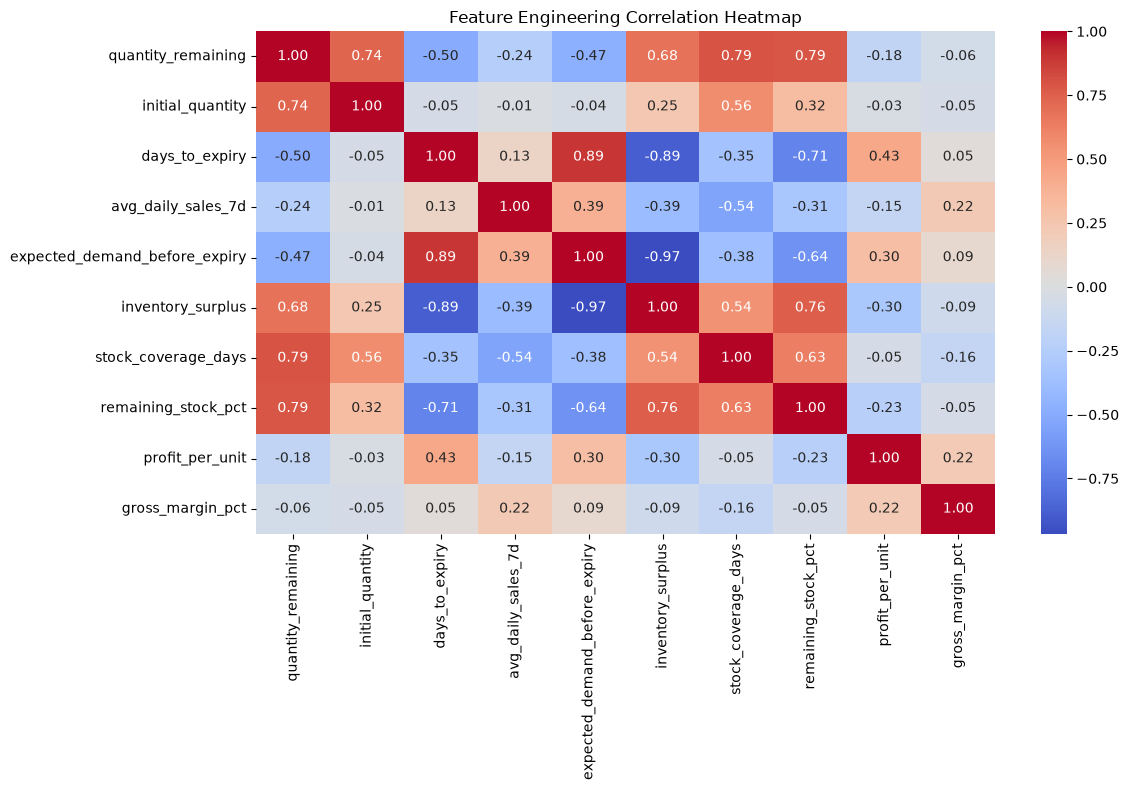

In [17]:
correlation_columns = [
    "quantity_remaining",
    "initial_quantity",
    "days_to_expiry",
    "avg_daily_sales_7d",
    "expected_demand_before_expiry",
    "inventory_surplus",
    "stock_coverage_days",
    "remaining_stock_pct",
    "profit_per_unit",
    "gross_margin_pct"
]

correlation_matrix = feature_df[
    correlation_columns
].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Engineering Correlation Heatmap")
plt.tight_layout()
plt.show()

In [18]:
feature_df.to_csv(
    PROCESSED_DIR / "inventory_features.csv",
    index=False
)

print("Updated feature dataset saved!")
print("Dataset shape:", feature_df.shape)

Updated feature dataset saved!
Dataset shape: (2000, 28)


In [19]:
feature_df["potential_expiry_pressure"] = np.where(
    feature_df["days_to_expiry"] < 0,
    "Already Expired",
    np.where(
        feature_df["days_to_expiry"] == 0,
        "Expires Today - Immediate Review",
        np.where(
            feature_df["stock_coverage_days"] >
            feature_df["days_to_expiry"],
            "Potential Excess Before Expiry",
            "Coverage Within Expiry Window"
        )
    )
)

display(
    feature_df["potential_expiry_pressure"].value_counts()
)

potential_expiry_pressure
Coverage Within Expiry Window       855
Potential Excess Before Expiry      536
Already Expired                     409
Expires Today - Immediate Review    200
Name: count, dtype: int64

In [20]:
print("Target distribution:")
display(feature_df["expiry_risk_label"].value_counts())

print("\nTarget percentages:")
display(
    feature_df["expiry_risk_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nWaste by target:")
display(
    pd.crosstab(
        feature_df["expiry_risk_label"],
        feature_df["waste_units_actual_simulated"] > 0,
        margins=True
    )
)

Target distribution:


expiry_risk_label
1    1172
0     828
Name: count, dtype: int64


Target percentages:


expiry_risk_label
1    58.6
0    41.4
Name: proportion, dtype: float64


Waste by target:


waste_units_actual_simulated,False,True,All
expiry_risk_label,,,
0,828,0,828
1,0,1172,1172
All,828,1172,2000


In [21]:
leakage_columns = [
    "waste_units_actual_simulated",
    "has_simulated_waste",
    "expiry_risk_label",
    "predicted_risk_rule"
]

existing_leakage_columns = [
    col for col in leakage_columns
    if col in feature_df.columns
]

print("Columns that must not be used as model inputs:")
print(existing_leakage_columns)

Columns that must not be used as model inputs:
['waste_units_actual_simulated', 'expiry_risk_label']


In [22]:
candidate_features = [
    "quantity_remaining",
    "initial_quantity",
    "days_to_expiry",
    "avg_daily_sales_7d",
    "expected_demand_before_expiry",
    "unit_price",
    "unit_cost",
    "discount_pct",
    "stock_coverage_days",
    "remaining_stock_pct",
    "profit_per_unit",
    "gross_margin_pct"
]

candidate_features = [
    col for col in candidate_features
    if col in feature_df.columns
]

X = feature_df[candidate_features].copy()
y = feature_df["expiry_risk_label"].copy()

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nMissing values:")
print(X.isnull().sum())

Input feature shape: (2000, 12)
Target shape: (2000,)

Input features:
['quantity_remaining', 'initial_quantity', 'days_to_expiry', 'avg_daily_sales_7d', 'expected_demand_before_expiry', 'unit_price', 'unit_cost', 'discount_pct', 'stock_coverage_days', 'remaining_stock_pct', 'profit_per_unit', 'gross_margin_pct']

Missing values:
quantity_remaining               0
initial_quantity                 0
days_to_expiry                   0
avg_daily_sales_7d               0
expected_demand_before_expiry    0
unit_price                       0
unit_cost                        0
discount_pct                     0
stock_coverage_days              0
remaining_stock_pct              0
profit_per_unit                  0
gross_margin_pct                 0
dtype: int64


In [23]:
ml_dataset = X.copy()
ml_dataset["expiry_risk_label"] = y

ml_dataset.to_csv(
    PROCESSED_DIR / "ml_preparation_dataset.csv",
    index=False
)

print("ML preparation dataset saved!")
print("Shape:", ml_dataset.shape)

ML preparation dataset saved!
Shape: (2000, 13)


In [24]:
# Convert snapshot_date into proper date format
feature_df["snapshot_date"] = pd.to_datetime(
    feature_df["snapshot_date"],
    errors="coerce"
)

# Check invalid dates
print("Invalid dates:", feature_df["snapshot_date"].isna().sum())

# Sort all unique dates
unique_dates = np.sort(
    feature_df["snapshot_date"].dropna().unique()
)

# Select the date for splitting
cutoff_position = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[cutoff_position]

# Create training and testing conditions
train_mask = feature_df["snapshot_date"] < cutoff_date
test_mask = feature_df["snapshot_date"] >= cutoff_date

X = feature_df[candidate_features].copy()
y = feature_df["expiry_risk_label"].copy()

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Cutoff Date:", cutoff_date)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Invalid dates: 0
Cutoff Date: 2026-10-07T00:00:00.000000
Training Shape: (1865, 12)
Testing Shape: (135, 12)

Training Target Distribution:
expiry_risk_label
1    1090
0     775
Name: count, dtype: int64

Testing Target Distribution:
expiry_risk_label
1    82
0    53
Name: count, dtype: int64


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [26]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities),
        "PR AUC": average_precision_score(y_test, probabilities)
    })

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.81      0.85        53
           1       0.89      0.94      0.91        82

    accuracy                           0.89       135
   macro avg       0.89      0.88      0.88       135
weighted avg       0.89      0.89      0.89       135


Random Forest
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        53
           1       0.90      0.90      0.90        82

    accuracy                           0.88       135
   macro avg       0.88      0.88      0.88       135
weighted avg       0.88      0.88      0.88       135



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.8889,0.8851,0.9390,0.9112,0.9535,0.9672
1,Random Forest,0.8815,0.9024,0.9024,0.9024,0.9374,0.9491


In [28]:
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

results_df.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison report saved successfully!")

Model comparison report saved successfully!


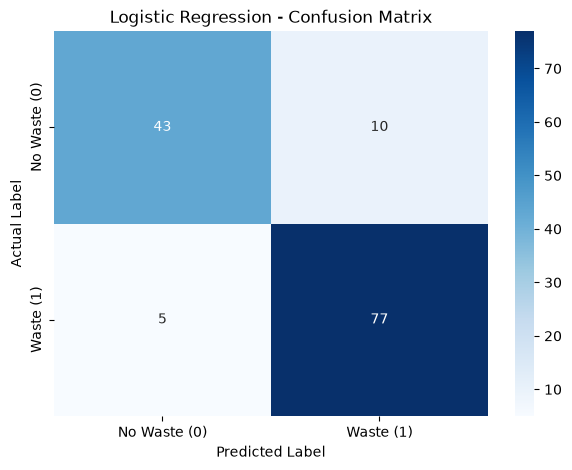

Confusion Matrix:
[[43 10]
 [ 5 77]]


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Predictions from Logistic Regression
y_pred = logistic_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Waste (0)", "Waste (1)"],
    yticklabels=["No Waste (0)", "Waste (1)"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, dummy_predictions), 4))

print("Baseline F1 Score:",
      round(f1_score(y_test, dummy_predictions), 4))

print("\nLogistic Regression Accuracy:",
      round(accuracy_score(y_test, logistic_model.predict(X_test)), 4))

print("Logistic Regression F1 Score:",
      round(f1_score(y_test, logistic_model.predict(X_test)), 4))

Baseline Accuracy: 0.6074
Baseline F1 Score: 0.7558

Logistic Regression Accuracy: 0.8889
Logistic Regression F1 Score: 0.9112


In [31]:
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(
    logistic_model,
    MODEL_DIR / "expiry_risk_logistic_regression.pkl"
)

# Save the feature names in their exact order
joblib.dump(
    candidate_features,
    MODEL_DIR / "expiry_risk_features.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [33]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

print("Project directory:", PROJECT_DIR)
print("Models folder:", PROJECT_DIR / "models")

print("\nFiles inside models folder:")

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

for file in MODEL_DIR.iterdir():
    print(file.name)

Project directory: c:\Users\hp\OneDrive\Desktop\WasteWise AI
Models folder: c:\Users\hp\OneDrive\Desktop\WasteWise AI\models

Files inside models folder:
expiry_risk_features.pkl
expiry_risk_logistic_regression.pkl


In [34]:
print("Searching for model files...\n")

for file in PROJECT_DIR.rglob("*"):
    if file.is_file() and file.suffix in [".pkl", ".joblib"]:
        print(file)

Searching for model files...

c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py27_np17.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py33_np18.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py34_np19.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py35_np19.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.11.0_pickle_py36_np111.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np16.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np17.pkl
c:\Users\hp\OneDrive\Desktop\WasteWise AI\.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py33_np18.pkl
c:\Users\hp\OneDrive\Desktop